# 31 — Regional covariance-targeting sensitivity

Compare the FX-only model's **free covariance intercept**, a **fitted-innovation second-moment
target**, and a **centered-return covariance target** for **Poland, Czechia, Romania, Sweden and
Hungary**, in **USD/EUR**, under **scalar and diagonal BEKK**: **60 cases, 40 new targeted fits**.
Keep the frozen **October 2014–September 2026 (144 months)** common sample, base kernel, corrected
FX means, zero alphas and constant world/local prices. No fetching or new instruments.

This is a two-step sensitivity, following the distinction used in Hungarian notebook 15. A fixed
sample target changes the estimator; reparameterizing a free intercept does not. Target-estimation
uncertainty is propagated in the primary tests. Target-fixed uncertainty is a labelled comparison.
The [regional_covariance_targeting.py](regional_covariance_targeting.py) wrapper reuses the existing
priced-mean/state filter and differentiates its target-to-intercept map. Previous files stay pinned.

In [1]:
# Fixed common sample; adjustable numerical and diagnostic controls.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70)]
MAX_ITER = 3000
MAX_ITER_OVERRIDES = {}
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)
REUSE_FITS = True
MODEL_VERSION = "regional_covariance_targets_v3"
WORLD_INSTRUMENTS = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
TARGETS = ["innovations", "returns"]
PD_FLOOR = 1e-8
MAX_TARGET_ROUNDS = 4
PREVIOUS_MANIFEST_SHA = "9009af58ec4534a179e10bbce8e54974a4119244f2cfc38ad3968d9ae4916fcb"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 20–22 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import pricing_robustness as core
importlib.reload(core)
import regional_local_pricing as engine
importlib.reload(engine)
import regional_fx_robustness as stress
importlib.reload(stress)
import regional_covariance_targeting as targeting
importlib.reload(targeting)
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
LOCAL_CURRENCIES = {"PL": "PLN", "CZ": "CZK", "RO": "RON", "SE": "SEK", "HU": "HUF"}
COUNTRY_ORDER, CURRENCIES, COVARIANCES = ["HU", "PL", "CZ", "RO", "SE"], ["USD", "EUR"], ["scalar", "diagonal"]
ASSETS = ["World", "US", "National", "National FX", "Other FX"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
PREVIOUS = ROOT/"output/30_regional_FX_targeted_robustness/2014-10_2026-09/targeted_e11bdda3"
assert TARGETS == ["innovations", "returns"] and PD_FLOOR > 0 and MAX_TARGET_ROUNDS >= 2
spec = {"targets": TARGETS, "denominator": "T", "innovation_target": "uncentered fitted-innovation second moment",
        "PD_floor": PD_FLOOR, "equity_alphas": "fixed zero", "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA}
instrument_id = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:8]
OUT = ROOT/"output/31_regional_covariance_targeting/2014-10_2026-09"/f"targets_{instrument_id}"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_hashes = {name: sha((ROOT/name).read_bytes()) for name in
    ["regional_covariance_targeting.py", "regional_fx_robustness.py", "regional_pricing_errors.py", "regional_local_pricing.py", "regional_fx_price_variation.py", "regional_world_pricing.py", "regional_currency_pricing.py", "pricing_robustness.py", "regional_pricing_baseline.py", "regional_covariance_sensitivity.py"]}
assert 2 <= TEST_LAGS <= 24 and tuple(HAC_LAGS) == (0, 3, 6, 12)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
print("Zero-alpha pricing engine SHA-256:", engine_hashes["regional_local_pricing.py"])

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Zero-alpha pricing engine SHA-256: f19326824d977a250770428f9951223e8219d5fdebb63b07aeff9e462757b2fb


## 1. Verify the frozen sample, FX designs and free-model references

Use notebook 30's unweighted baseline rows only. Every return and instrument date, scale, lag and
normalizer stays fixed. Re-filter all 20 free-intercept estimates and verify means, covariances,
innovations, scores, zero alphas and projected gradients. Reuse the verified first-stage Hessians;
retain the first-stage numerical limitations when propagating innovation-target uncertainty.

In [2]:
def verify_inputs():
    raw = (PREVIOUS/"estimation_manifest.json").read_bytes()
    if sha(raw) != PREVIOUS_MANIFEST_SHA: raise ValueError("Notebook-30 manifest changed.")
    previous = json.loads(raw)
    assert previous["input_locks"] == LOCK_HASHES
    assert (previous["first"], previous["last"], previous["observations_per_state_path"]) == ("2014-10", "2026-09", 144)
    expected = previous["input_file_hashes"].copy()
    for name, checksum in previous["outputs"].items():
        expected[(PREVIOUS/name).relative_to(ROOT).as_posix()] = checksum
    expected[(PREVIOUS/"estimation_manifest.json").relative_to(ROOT).as_posix()] = PREVIOUS_MANIFEST_SHA
    expected.update(previous["engines"])
    locks = {}
    for name, checksum in LOCK_HASHES.items():
        content = (ROOT/name).read_bytes()
        if sha(content) != checksum: raise ValueError(f"Changed input lock: {name}")
        locks[name] = json.loads(content)
    for path, checksum in expected.items():
        if sha((ROOT/path).read_bytes()) != checksum: raise ValueError(f"Changed frozen input: {path}")
    regional = locks["regional_dataset_inputs.json"]
    assert sha((ROOT/regional["root"]/"manifest.json").read_bytes()) == regional["manifest_sha256"]
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes, audit_rows = {}, {}, {}, {}, []
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT/regional["root"]/"common"/f"{country}_{currency}.csv"
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[path.relative_to(ROOT).as_posix()]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all() and d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"]-d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local", "fx_local", "fx_other"]].to_numpy()*100
        scale = y.std(axis=0, ddof=1)
        correlation = np.cov(y, rowvar=False)/np.outer(scale, scale)
        assert (scale > 0).all() and np.linalg.eigvalsh(correlation).min() > 0 and np.linalg.matrix_rank(y-y.mean(axis=0)) == 5
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, scale, sha(raw)
        np.testing.assert_array_equal(y[:, [0, 1, 4]], samples[("HU", currency)][:, [0, 1, 4]])
        audit_rows.append({"country": country, "name": NAMES[country], "perspective": currency,
            "first": str(months[0]), "last": str(months[-1]), "months": len(y), "rank": 5,
            "min_correlation_eigenvalue": np.linalg.eigvalsh(correlation).min(), "correlation_condition": np.linalg.cond(correlation),
            "national_FX_sd_pp": scale[3], "national_FX_currency": LOCAL_CURRENCIES[country],
            "other_FX_currency": "EUR" if currency == "USD" else "USD"})
transform = np.eye(5)
transform[:3, 4], transform[3, 4], transform[4, 4] = -1., -1., -1.
for country in COUNTRY_ORDER:
    converted = samples[(country, "USD")]@transform.T
    converted[:, :3] += ((frames[(country, "USD")].rf-frames[(country, "EUR")].rf)*100).to_numpy()[:, None]
    np.testing.assert_allclose(converted, samples[(country, "EUR")], atol=1e-10, rtol=0)
input_audit = pd.DataFrame(audit_rows)
display(input_audit.set_index(["name", "perspective"])[["months", "rank", "correlation_condition", "national_FX_sd_pp", "other_FX_currency"]].round(4))
print("Verified", len(input_hashes), "protected files and all ten five-series input systems.")

months  rank  correlation_condition  national_FX_sd_pp  \
name    perspective                                                           
Hungary USD             144     5               177.8975             3.0207   
        EUR             144     5               123.6042             1.7874   
Poland  USD             144     5               196.7334             2.9611   
        EUR             144     5               135.7310             1.4953   
Czechia USD             144     5               218.7463             2.6464   
        EUR             144     5               152.3439             1.1305   
Romania USD             144     5               168.0376             2.1759   
        EUR             144     5               110.8968             0.5283   
Sweden  USD             144     5               242.4797             2.9674   
        EUR             144     5               174.9449             1.7097   

                    other_FX_currency  
name    perspective                    
Hungary USD                       EUR  
        EUR                       USD  
Poland  USD                       EUR  
        EUR                       USD  
Czechia USD                       EUR  
        EUR                       USD  
Romania USD                       EUR  
        EUR                       USD  
Sweden  USD                       EUR  
        EUR                       USD

Verified 2379 protected files and all ten five-series input systems.


In [3]:
source_design = pd.read_csv(PREVIOUS/"conditioning_design.csv", float_precision="round_trip").query("variant == 'baseline'")
source_quality = pd.read_csv(PREVIOUS/"inflation_quality_weights.csv").query("variant == 'baseline'")
designs, names_by, first_original, first_stages = {}, {}, {}, {}
reference_rows, design_rows = [], []
for key in samples:
    country, currency = key
    designs[key], names_by[key] = {"W": np.ones((len(months), 1))}, {"W": ["constant"]}
    for a in ["H", "O"]:
        g = source_design.query("country == @country and perspective == @currency and factor == @a")
        nn = list(g.instrument.unique())
        assert all(g.loc[g.instrument.eq(n), "month"].tolist() == months.astype(str).tolist() for n in nn)
        D = np.array(np.column_stack([g.loc[g.instrument.eq(n), "value"] for n in nn]), order="F")
        assert np.isfinite(D).all() and np.linalg.matrix_rank(D) == D.shape[1]
        designs[key][a], names_by[key][a] = D, nn
        design_rows.append({"country": country, "perspective": currency, "factor": a, "columns": D.shape[1], "rank": np.linalg.matrix_rank(D), "condition": np.linalg.cond(D), "design_sha256": sha(D.tobytes())})
    designs[key]["L"], names_by[key]["L"] = np.ones((len(months), 1)), ["constant"]
    for cov in COVARIANCES:
        path = PREVIOUS/f"parameters_{country}_{currency}_{cov}_baseline.npz"
        assert sha(path.read_bytes()) == input_hashes[path.relative_to(ROOT).as_posix()]
        with np.load(path, allow_pickle=False) as z:
            theta = z["theta"].copy()
            f = engine.filter_model(theta, samples[key], designs[key], scales[key], True, cov)
            np.testing.assert_array_equal(z["equity_alphas"], np.zeros(3)); np.testing.assert_array_equal(z["weights"], np.ones(len(months)))
            for field in ["H", "mu", "errors", "scores", "losses"]: np.testing.assert_allclose(f[field], z[field], atol=3e-12, rtol=1e-13)
            hessians = z["Hessian"].copy(), z["Hessian_small"].copy()
        limits = engine.bounds(designs[key], True, cov)
        pg = np.abs(engine.projected_gradient(theta, f["scores"].mean(axis=0), limits)).max(); assert pg < 1e-4
        first_original[(*key, cov)] = {"theta": theta.copy(), "filter": f, "hessians": hessians, "source": path.relative_to(ROOT).as_posix(), "source_sha256": sha(path.read_bytes())}
        first_stages[(*key, cov)] = {**first_original[(*key, cov)], "origin": "notebook 30 baseline"}
        reference_rows.append({"country": country, "perspective": currency, "covariance": cov, "loglik": -f["losses"].sum(), "projected_gradient": pg,
            "source": path.relative_to(ROOT).as_posix(), "source_sha256": sha(path.read_bytes())})
reference_audit, design_audit = pd.DataFrame(reference_rows), pd.DataFrame(design_rows)
display(design_audit.set_index(["country", "perspective", "factor"]).round(5))
print(f"Verified {len(first_stages)} free references and all fixed FX designs.", flush=True)

columns  rank  condition  \
country perspective factor                             
HU      USD         H             5     5    1.96253   
                    O             5     5    2.07291   
        EUR         H             5     5    1.91561   
                    O             5     5    2.07291   
PL      USD         H             5     5    1.86216   
                    O             5     5    2.07291   
        EUR         H             5     5    1.88369   
                    O             5     5    2.07291   
CZ      USD         H             6     6    1.84639   
                    O             5     5    2.07291   
        EUR         H             6     6    1.83002   
                    O             5     5    2.07291   
RO      USD         H             5     5    1.83656   
                    O             5     5    2.07291   
        EUR         H             5     5    1.80216   
                    O             5     5    2.07291   
SE      USD         H             5     5    1.87095   
                    O             5     5    2.07291   
        EUR         H             5     5    1.83995   
                    O             5     5    2.07291   

                                                                design_sha256  
country perspective factor                                                     
HU      USD         H       5081ebc7faba24b7265d6fa980acd0da2fed5891d3ef00...  
                    O       22bc5151a9a9cfd80e73ff9546b3622433a475cec8ad9b...  
        EUR         H       7dc88616d2f4e8bef853e2ceeae7ed8e90915ebdd0777a...  
                    O       a699c74ae5cfef82020e5c23c1a44d37ce8b08112ff09e...  
PL      USD         H       4a747f16304a60ca71127ced1c113fe616317ee8e4d9a3...  
                    O       22bc5151a9a9cfd80e73ff9546b3622433a475cec8ad9b...  
        EUR         H       a37e2ea97e3c9db1183b96ddf91637cadb943f085b1c87...  
                    O       a699c74ae5cfef82020e5c23c1a44d37ce8b08112ff09e...  
CZ      USD         H       bd2835d946752e4f19a8384ab47a141b143ddd35a3b884...  
                    O       22bc5151a9a9cfd80e73ff9546b3622433a475cec8ad9b...  
        EUR         H       80c3671023c5503f7277baf7e207db6dbbb089eb01d522...  
                    O       a699c74ae5cfef82020e5c23c1a44d37ce8b08112ff09e...  
RO      USD         H       25238684c15e7fd2dc37f0908ed251af03ff025bb72ea9...  
                    O       22bc5151a9a9cfd80e73ff9546b3622433a475cec8ad9b...  
        EUR         H       eb8c82198e2f4cd365e13277fb037e1956de601986221a...  
                    O       a699c74ae5cfef82020e5c23c1a44d37ce8b08112ff09e...  
SE      USD         H       c2518de69d3d3a4c4e69f1641ae7dc5115deb3e1ee7d0e...  
                    O       22bc5151a9a9cfd80e73ff9546b3622433a475cec8ad9b...  
        EUR         H       49fdee969329b65f3cd074534e130d9023df08578d3f3e...  
                    O       a699c74ae5cfef82020e5c23c1a44d37ce8b08112ff09e...

Verified 20 free references and all fixed FX designs.


## 2. Define targets and verify the map and its derivatives

Let $\hat\eta$ denote the preliminary free-intercept fit and $\hat\epsilon_t^F=y_t-\mu_t(\hat\eta)$.
Use $T$, not $T-1$, in both target definitions:

$$\boxed{\hat S_{innov}=T^{-1}\sum_t\hat\epsilon_t^F\hat\epsilon_t^{F\prime},\qquad
\hat S_{returns}=T^{-1}\sum_t(y_t-\bar y)(y_t-\bar y)'.}$$

Do **not** demean fitted innovations. The return target is a different benchmark: unconditional
return covariance also reflects variation in conditional means. Each innovation target uses its own
covariance model's preliminary fit; scalar/diagonal innovation targets therefore need not coincide.

For $A=\operatorname{diag}(\sqrt\alpha)$ and $B=\operatorname{diag}(\sqrt\beta)$:

$$\boxed{\Omega=\hat S-A\hat S A'-B\hat S B',\quad
H_t=\Omega+A\epsilon_{t-1}\epsilon_{t-1}'A'+BH_{t-1}B',\quad H_1=\hat S.}$$

Keep the smallest eigenvalue of the SD-normalized intercept above `PD_FLOOR`. A positive target and
stationary diagonal dynamics alone do not guarantee a positive intercept. No target repair or silent
shrinkage is applied. Targeting removes 15 intercept coordinates from stage two: **15/23 scalar/diagonal
parameters**, or **16/24 for Czechia**; the 15 target moments are still estimated.

In [4]:
def make_case(key, cov, kind, first):
    y, scale = samples[key], scales[key]
    error = first["filter"]["errors"] if kind == "innovations" else y-y.mean(axis=0)
    S = error.T@error/len(y); target = S/np.outer(scale, scale)
    assert np.linalg.eigvalsh(target).min() > 0
    return {"country": key[0], "perspective": key[1], "covariance": cov, "target_kind": kind,
        "id": f"{key[0]}_{key[1]}_{cov}_{kind}", "y": y, "scales": scale, "designs": designs[key], "names": names_by[key], "target": target}
def args(c): return c["y"], c["designs"], c["scales"], c["covariance"], c["target"]
def target_audit_row(c, first, round_number):
    t = c["target"]; scale = np.outer(c["scales"], c["scales"])
    return {"country": c["country"], "perspective": c["perspective"], "covariance": c["covariance"], "target_kind": c["target_kind"], "round": round_number,
        "minimum_normalized_eigenvalue": np.linalg.eigvalsh(t).min(), "normalized_condition": np.linalg.cond(t),
        "relative_distance_from_free_target": np.linalg.norm(t-first["filter"]["target"]/scale)/np.linalg.norm(first["filter"]["target"]/scale), "target_sha256": sha(t.tobytes())}
check_rows = []
for fk, first in first_stages.items():
    key, cov = fk[:2], fk[2]
    for kind in TARGETS:
        c = make_case(key, cov, kind, first)
        probe = targeting.reduce_free(engine.initial_theta(c["y"], c["designs"], c["scales"], True, cov, alpha=.1, beta=.7), c["designs"], cov)
        for ix in engine.price_indices(c["designs"], True).values(): probe[ix[1:]] = np.linspace(.1, -.08, len(ix)-1)
        if cov == "diagonal": probe[-10:] += np.linspace(-.003, .003, 10)
        probe = targeting.feasible_start(probe, c["designs"], cov, c["target"], PD_FLOOR)
        sub = c["y"][:35], {a: d[:35] for a, d in c["designs"].items()}, c["scales"], cov, c["target"]
        analytic = targeting.objective(probe, *sub)[1]
        numeric = engine.numerical_gradient(lambda t: targeting.objective(t, *sub)[0], probe)
        np.testing.assert_allclose(analytic, numeric, atol=5e-6, rtol=5e-5)
        full, J = targeting.free_map(probe, c["designs"], cov, c["target"])
        Jn = targeting.jacobian(lambda t: targeting.free_map(t, c["designs"], cov, c["target"])[0], probe, step=1e-5)
        np.testing.assert_allclose(J, Jn, atol=2e-7, rtol=2e-5)
        f = targeting.filter_model(probe, *sub)
        direct = targeting.direct_filter(probe, *sub)
        for field in ["H","mu","errors","losses","scores"]: np.testing.assert_allclose(direct[field],f[field],atol=1e-9,rtol=1e-9)
        np.testing.assert_allclose(f["target"], c["target"]*np.outer(c["scales"], c["scales"]), atol=1e-8, rtol=1e-10)
        margin, cg = targeting.constraint(probe, c["designs"], cov, c["target"], PD_FLOOR)
        cn = engine.numerical_gradient(lambda t: targeting.constraint(t, c["designs"], cov, c["target"], PD_FLOOR)[0], probe)
        np.testing.assert_allclose(cg, cn, atol=1e-7, rtol=1e-5)
        check_rows.append({"country": fk[0], "perspective": fk[1], "covariance": cov, "target_kind": kind, "stage2_parameters": len(probe),
            "score_error": np.abs(analytic-numeric).max(), "map_Jacobian_error": np.abs(J-Jn).max(), "PD_constraint_gradient_error": np.abs(cg-cn).max()})
checks = pd.DataFrame(check_rows); display(checks.round(7))

,country,perspective,covariance,target_kind,stage2_parameters,score_error,map_Jacobian_error,PD_constraint_gradient_error
0,HU,USD,scalar,innovations,15,0.0,0.0,0.0
1,HU,USD,scalar,returns,15,0.0,0.0,0.0
2,HU,USD,diagonal,innovations,23,0.0,0.0,0.0
3,HU,USD,diagonal,returns,23,0.0,0.0,0.0
4,HU,EUR,scalar,innovations,15,0.0,0.0,0.0
5,HU,EUR,scalar,returns,15,0.0,0.0,0.0
6,HU,EUR,diagonal,innovations,23,0.0,0.0,0.0
7,HU,EUR,diagonal,returns,23,0.0,0.0,0.0
8,PL,USD,scalar,innovations,15,0.0,0.0,0.0
9,PL,USD,scalar,returns,15,0.0,0.0,0.0


## 3. Jointly re-estimate prices and retained dynamics

Use the mapped free reference, two moment/dynamics points and a scalar-structure point for diagonal
fits. Adjust only starting dynamics toward common coefficients if necessary for intercept feasibility.
Require optimizer success, feasibility and a small bound/PD-constraint KKT gradient; keep raw gradients
and multipliers visible. At multiple active eigenvalues, validate a full PSD-cone dual certificate,
including primal/dual feasibility and complementarity; one minimum-eigenvalue multiplier is insufficient.
A lower feasible unconverged candidate stops the run. Exact caches include every
target, starting point, preliminary estimate, input array, engine/software hash and numerical setting.

If a targeted point maps within the free model's numerical bounds and improves its comparator, refine
the free comparator **in this output folder** and recompute its innovation target. Record every round;
old references stay unchanged. Different covariance models' innovation targets are not nested. The
centered-return target is shared, so scalar-to-diagonal nesting is checked for that target.

In [5]:
cases, fits, run_rows, cache_files, target_rows, free_audit_rows, refinement_rows = {}, {}, [], [], [], [], []
def read_cache(path):
    if not REUSE_FITS or not path.exists(): return None
    try: return json.loads(path.read_text())
    except (OSError, json.JSONDecodeError): return None
def atomic_json(path, record):
    temp = path.with_suffix(".tmp"); temp.write_text(json.dumps(record, indent=2, sort_keys=True)+chr(10)); temp.replace(path)
def fit_target(c, first, round_number):
    key = c["country"], c["perspective"], c["covariance"], c["target_kind"]
    starts = [("mapped free", targeting.reduce_free(first["theta"], c["designs"], c["covariance"]))]
    starts += [(f"moment {a:g}/{b:g}", targeting.reduce_free(engine.initial_theta(c["y"], c["designs"], c["scales"], True, c["covariance"], alpha=a, beta=b), c["designs"], c["covariance"])) for a,b in START_DYNAMICS]
    if c["covariance"] == "diagonal":
        scalar = fits[(key[0], key[1], "scalar", key[3])]["theta"]
        k = targeting.layout(c["designs"], "scalar")[0]
        starts.append(("scalar structure", np.r_[scalar[:k], np.tile(scalar[-2:], 5)]))
    starts = [(n, targeting.feasible_start(p, c["designs"], c["covariance"], c["target"], PD_FLOOR)) for n,p in starts]
    config = {"version": MODEL_VERSION, "case": c["id"], "round": round_number, "engines": engine_hashes, "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA,
        "columns": c["names"], "first_theta_sha256": sha(first["theta"].tobytes()), "start_labels": [n for n,_ in starts], "start_hashes": [sha(p.tobytes()) for _,p in starts],
        "max_iter": MAX_ITER_OVERRIDES.get(key, MAX_ITER), "PD_floor": PD_FLOOR, "packages": versions, "python": platform.python_version(), "spec": spec}
    payload = c["y"].tobytes()+c["target"].tobytes()+b"".join(c["designs"][a].tobytes() for a in ["W","H","O","L"])
    fingerprint = sha(json.dumps(config, sort_keys=True).encode()+payload)
    name = f"fit_{c['id']}_round{round_number}.json"; path = OUT/name; record = read_cache(path)
    limits = targeting.bounds(c["designs"], c["covariance"])
    if record is not None and record.get("fingerprint") == fingerprint and np.asarray(record.get("theta", [])).shape == (len(limits),):
        t = np.asarray(record["theta"]); value,g = targeting.objective(t,*args(c)); margin,cg = targeting.constraint(t,c["designs"],c["covariance"],c["target"],PD_FLOOR)
        cert = targeting.kkt_certificate(t,g,c["designs"],c["covariance"],c["target"],PD_FLOOR,dual=np.asarray(record["PD_dual_matrix"]))
        if not (record["optimizer_success"] and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8 and margin >= -1e-10
            and ((t>=limits[:,0]) & (t<=limits[:,1])).all() and cert["KKT_gradient"] < 1e-4
            and cert["dual_min_eigenvalue"] >= -1e-8 and cert["complementarity"] < 1e-6): record = None
    else: record = None
    print(f"{c['id']} · round {round_number} · {'verified cache' if record else 'optimizing'}", flush=True)
    if record is None:
        best,runs = targeting.fit_starts(args(c), [p for _,p in starts], maxiter=config["max_iter"], pd_floor=PD_FLOOR)
        margin,_ = targeting.constraint(best.x,c["designs"],c["covariance"],c["target"],PD_FLOOR)
        record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(), "mean_nll": float(best.fun), "optimizer_success": bool(best.success), "PD_dual_matrix":best["PD_dual_matrix"].tolist(), "starts": runs}
        atomic_json(path,record)
    theta = np.asarray(record["theta"]); f = targeting.filter_model(theta,*args(c))
    assert f["losses"].mean() <= min(targeting.objective(p,*args(c))[0] for _,p in starts)+1e-7
    run_rows.extend({"country":key[0],"perspective":key[1],"covariance":key[2],"target_kind":key[3],"round":round_number,"start_label":starts[r["start"]-1][0],**r} for r in record["starts"])
    cache_files.append(name)
    return {"theta":theta,"filter":f,"PD_dual_matrix":np.asarray(record["PD_dual_matrix"]),"round":round_number}
def refine_free(fk, first, candidates, round_number):
    key,cov = fk[:2],fk[2]; starts = [("current free",first["theta"])]+candidates
    config = {"version":MODEL_VERSION,"case":f"{fk[0]}_{fk[1]}_{cov}_free","round":round_number,"engines":engine_hashes,
        "start_labels":[n for n,_ in starts],"start_hashes":[sha(p.tobytes()) for _,p in starts],"max_iter":MAX_ITER,"packages":versions,"python":platform.python_version()}
    fingerprint = sha(json.dumps(config,sort_keys=True).encode()+samples[key].tobytes()+b"".join(designs[key][a].tobytes() for a in ["W","H","O","L"]))
    name=f"free_refinement_{fk[0]}_{fk[1]}_{cov}_round{round_number}.json";path=OUT/name;record=read_cache(path)
    aa=samples[key],designs[key],scales[key],True,cov;limits=engine.bounds(designs[key],True,cov)
    if record is None or record.get("fingerprint")!=fingerprint:
        best,runs=engine.fit_starts(*aa,starts=[p for _,p in starts],maxiter=MAX_ITER)
        record={"fingerprint":fingerprint,"config":config,"theta":best.x.tolist(),"mean_nll":float(best.fun),"optimizer_success":bool(best.success),"starts":runs};atomic_json(path,record)
    t=np.asarray(record["theta"]);value,g=engine.objective(t,*aa)
    assert record["optimizer_success"] and abs(value-record["mean_nll"])<1e-8 and np.abs(engine.projected_gradient(t,g,limits)).max()<1e-4
    assert ((t>=limits[:,0]) & (t<=limits[:,1])).all() and value<=min(engine.objective(p,*aa)[0] for _,p in starts)+1e-7
    cache_files.append(name);f=engine.filter_model(t,*aa)
    refinement_rows.append({"country":fk[0],"perspective":fk[1],"covariance":cov,"round":round_number,"before_mean_nll":first["filter"]["losses"].mean(),"after_mean_nll":value})
    return {**first,"theta":t,"filter":f,"hessians":None,"origin":"refined free comparator"}
for fk in first_stages:
    key,cov=fk[:2],fk[2];first=first_stages[fk]
    if cov=="diagonal":
        scalar=first_stages[(*key,"scalar")]
        nested=engine.expand_scalar(scalar["theta"])
        if engine.objective(nested,samples[key],designs[key],scales[key],True,cov)[0]<first["filter"]["losses"].mean()-1e-7:
            first=refine_free(fk,first,[("nested scalar free",nested)],0)
    for round_number in range(1,MAX_TARGET_ROUNDS+1):
        improving=[]
        for kind in TARGETS:
            c=make_case(key,cov,kind,first);fit=fit_target(c,first,round_number);tk=(*fk,kind)
            cases[tk],fits[tk]=c,fit;target_rows.append(target_audit_row(c,first,round_number))
            full=fit["filter"]["free_theta"];limits=engine.bounds(c["designs"],True,cov)
            feasible=bool(((full>=limits[:,0]) & (full<=limits[:,1])).all())
            gain=len(months)*(first["filter"]["losses"].mean()-fit["filter"]["losses"].mean())
            free_audit_rows.append({"country":fk[0],"perspective":fk[1],"covariance":cov,"target_kind":kind,"round":round_number,"within_free_bounds":feasible,"loglik_gain_target_vs_free":gain})
            if feasible and gain>len(months)*1e-7:improving.append(("mapped "+kind,full))
        if not improving:break
        first=refine_free(fk,first,improving,round_number)
    else:raise RuntimeError("Target/free consistency did not stabilize; inspect rounds.")
    first_stages[fk]=first
    freecase={"country":key[0],"perspective":key[1],"covariance":cov,"target_kind":"free","id":f"{key[0]}_{key[1]}_{cov}_free","y":samples[key],"scales":scales[key],"designs":designs[key],"names":names_by[key]}
    cases[(*fk,"free")]=freecase;fits[(*fk,"free")]=first
    if cov=="diagonal":
        r=fits[(*key,"scalar","returns")]["filter"]["losses"].sum()-fits[(*fk,"returns")]["filter"]["losses"].sum()
        assert r>=-2e-5
target_audit=pd.DataFrame(target_rows);free_comparator_audit=pd.DataFrame(free_audit_rows)
refinements=pd.DataFrame(refinement_rows,columns=["country","perspective","covariance","round","before_mean_nll","after_mean_nll"])
starting_points=pd.DataFrame(run_rows,columns=["country","perspective","covariance","target_kind","round","start_label","start","attempt","success","valid","feasible","mean_nll","raw_gradient","KKT_gradient","PD_margin","PD_multiplier","dual_min_eigenvalue","complementarity","iterations","message"])
display(target_audit.round(6));display(refinements);print(f"Final grid: {len(fits)} cases.",flush=True)

HU_USD_scalar_innovations · round 1 · verified cache


HU_USD_scalar_returns · round 1 · verified cache


HU_USD_diagonal_innovations · round 1 · verified cache


HU_USD_diagonal_returns · round 1 · verified cache


HU_EUR_scalar_innovations · round 1 · verified cache


HU_EUR_scalar_returns · round 1 · verified cache


... (33 outputs left out)

SE_EUR_diagonal_returns · round 1 · verified cache


,country,perspective,covariance,target_kind,round,minimum_normalized_eigenvalue,normalized_condition,relative_distance_from_free_target,target_sha256
0,HU,USD,scalar,innovations,1,0.018391,174.851783,0.035571,e2cda0801799c380f28e326a39589a0226ffba34f3793f...
1,HU,USD,scalar,returns,1,0.018321,177.897462,0.035138,25f849d914465ce8b274cc96c8e0c501c51c412a565903...
2,HU,USD,diagonal,innovations,1,0.018364,175.958223,0.042181,7087da75d3ac029f7b04253125277dd61073caf1f6b726...
3,HU,USD,diagonal,returns,1,0.018321,177.897462,0.030459,25f849d914465ce8b274cc96c8e0c501c51c412a565903...
4,HU,EUR,scalar,innovations,1,0.020529,120.380703,0.042861,022d778bc7069205766971a19d1e3c290fca9a3017d67a...
5,HU,EUR,scalar,returns,1,0.020479,123.604188,0.061671,3506a11e8d7077ba457057b6d0893cabed5fa002d0dce6...
6,HU,EUR,diagonal,innovations,1,0.020410,123.743712,0.034419,c3093e1daeda16b2078e07eb5090b1c46a68073d0a7ead...
7,HU,EUR,diagonal,returns,1,0.020479,123.604188,0.032429,3506a11e8d7077ba457057b6d0893cabed5fa002d0dce6...
8,PL,USD,scalar,innovations,1,0.017927,191.470405,0.065801,9c8fad6bba3c2caaf0d34ea53677002b7477621b5c9858...
9,PL,USD,scalar,returns,1,0.017874,196.733428,0.073611,b20c614ba0649ced0e132f8d6336476169a87ee809e584...


,country,perspective,covariance,round,before_mean_nll,after_mean_nll


Final grid: 60 cases.


## 4. Propagate estimated-target uncertainty

For innovation targets, stack preliminary free scores, target moments and second-stage scores:

$$\psi_t(\eta,s,\beta)=\begin{bmatrix}g_t^F(\eta)\\
s-\operatorname{vech}(u_t^F u_t^{F\prime})\\g_t^{target}(\beta,s)\end{bmatrix},
\quad u_t^F=\epsilon_t^F/\text{fixed sample SDs}.$$

With $D=\partial\bar\psi/\partial(\eta,s,\beta)'$ and full-calendar Bartlett HAC meat $S_L$,
the bottom block of $D^{-1}S_LD^{-1\prime}/T$ gives **target-adjusted** uncertainty, including all
cross-stage covariances. Centered-return targeting stacks its covariance moment and stage-two score;
estimating its unconditional mean has zero first-order derivative in that centered moment.

Keep HAC lags **0, 3, 6, 12**, two differentiation steps, coefficient/PD-bound checks, positive
likelihood curvature, stacked-Jacobian conditioning and coefficient/all-four-price-path SE checks.
Innovation-target inference inherits preliminary-estimator irregularity. Withhold invalid ordinary
tests with reasons. Target-fixed uncertainty is a comparison, not the primary result. All pricing
tests are exploratory; component Holm adjustment covers only the two currency blocks within each
case/bandwidth/hypothesis family. Cache stacked derivatives only with exact input/parameter/engine
fingerprints and integrity hashes; recalculate the sandwiches and gates on cache hits.

In [6]:
inference_rows,fit_rows,test_rows,coefficient_rows,path_rows,bound_rows=[],[],[],[],[],[]
def get_inference(fk,kind,c,fit,first):
    if kind=="free":
        info=stress.inference(fit["theta"],c["y"],c["designs"],c["scales"],c["covariance"],np.ones(len(months)),filtered=fit["filter"],hac_lags=HAC_LAGS,hessians=first["hessians"])
        first["hessians"]=(info["Hessian"],info["Hessian_small"])
        return {**info,"stack_Jacobian":info["Hessian"],"stack_Jacobian_small":info["Hessian_small"],"stack_scores":fit["filter"]["scores"],
            "Jacobian_condition":info["Hessian_condition"],"Jacobian_step_difference":info["Hessian_step_difference"],"PD_margin":np.linalg.eigvalsh(fit["filter"]["intercept"]/np.outer(c["scales"],c["scales"])).min()-PD_FLOOR,
            "estimates":{("joint_QML",h):e for h,e in info["estimates"].items()}}
    config={"version":MODEL_VERSION,"case":c["id"],"engines":engine_hashes,"packages":versions,"python":platform.python_version(),"steps":[1e-4,5e-5],"PD_floor":PD_FLOOR,"HAC_lags":list(HAC_LAGS)}
    payload=fit["theta"].tobytes()+first["theta"].tobytes()+c["y"].tobytes()+c["target"].tobytes()+b"".join(c["designs"][a].tobytes() for a in ["W","H","O","L"])
    fingerprint=sha(json.dumps(config,sort_keys=True).encode()+payload)
    name=f"derivatives_{c['id']}.npz";path=OUT/name;record_path=path.with_suffix(".json");record=read_cache(record_path);pair=None
    if path.exists() and record is not None and record.get("fingerprint")==fingerprint and record.get("npz_sha256")==sha(path.read_bytes()):
        with np.load(path,allow_pickle=False) as z:pair=tuple(z[a].copy() if a not in ["A0","small0"] or kind=="innovations" else None for a in ["A","A0","D","small","small0","Dsmall"])
    info=targeting.inference(fit["theta"],args(c),fit["filter"],kind,first["theta"],first["filter"],hac_lags=HAC_LAGS,pd_floor=PD_FLOOR,derivative_cache=pair,first_hessians=first["hessians"])
    if pair is None:
        arrays={n:(a if a is not None else np.empty((0,0))) for n,a in zip(["A","A0","D","small","small0","Dsmall"],info["derivative_cache"])}
        temp=path.with_suffix(".tmp.npz");np.savez(temp,**arrays);temp.replace(path)
        atomic_json(record_path,{"fingerprint":fingerprint,"config":config,"npz_sha256":sha(path.read_bytes())})
    cache_files.extend([name,record_path.name]);return info
# Free rows first: supply verified/refined first-stage Hessians to the target stacks.
ordered=sorted(fits,key=lambda k:(list(first_stages).index(k[:3]),["free","innovations","returns"].index(k[3])))
for tk in ordered:
    fk,kind=tk[:3],tk[3];c,fit=cases[tk],fits[tk];first=first_stages[fk]
    print("Inference:",c["id"],flush=True)
    info=get_inference(fk,kind,c,fit,first);fit["inference"]=info;primary="joint_QML" if kind=="free" else "target_adjusted"
    theta,f=fit["theta"],fit["filter"];ids=engine.price_indices(c["designs"],True);tags={"country":tk[0],"perspective":tk[1],"covariance":tk[2],"target_kind":kind}
    limits=engine.bounds(c["designs"],True,tk[2]) if kind=="free" else targeting.bounds(c["designs"],tk[2])
    value,g=(f["losses"].mean(),f["scores"].mean(axis=0)) if kind=="free" else targeting.objective(theta,*args(c))
    if kind=="free":kkt=np.abs(engine.projected_gradient(theta,g,limits)).max()
    else:
        margin,cg=targeting.constraint(theta,c["designs"],tk[2],c["target"],PD_FLOOR)
        cert=targeting.kkt_certificate(theta,g,c["designs"],tk[2],c["target"],PD_FLOOR,dual=fit["PD_dual_matrix"])
        kkt=cert["KKT_gradient"];assert cert["dual_min_eigenvalue"]>=-1e-8 and cert["complementarity"]<1e-6
    assert kkt<1e-4
    fit_rows.append({**tags,"n":len(months),"stage2_parameters":len(theta),"loglik":-f["losses"].sum(),"raw_gradient":np.abs(g).max(),"KKT_gradient":kkt,
        "PD_margin":info["PD_margin"],"Jacobian_condition":info["Jacobian_condition"],"Jacobian_step_difference":info["Jacobian_step_difference"],"min_H_eigenvalue":np.linalg.eigvalsh(f["H"]).min(),
        "primary_method":primary,"primary_inference_ready":info["estimates"][(primary,0)]["ready"],"primary_reason":info["estimates"][(primary,0)]["reason"],
        "first_stage_refined":not np.array_equal(first["theta"],first_original[fk]["theta"])})
    distance=np.minimum(theta-limits[:,0],limits[:,1]-theta)
    bound_rows.extend({**tags,"position":j,"coordinate":theta[j],"lower":limits[j,0],"upper":limits[j,1],"distance_to_bound":distance[j],"near_bound":bool(distance[j]<1e-4)} for j in range(len(theta)))
    restrictions={"FX prices constant":np.r_[ids["H"][1:],ids["O"][1:]],"FX prices jointly zero":np.r_[ids["H"],ids["O"]],"National FX price constant":ids["H"][1:],"Other FX price constant":ids["O"][1:],
        "National FX price zero":ids["H"],"Other FX price zero":ids["O"],"World price zero":ids["W"],"National local price zero":ids["L"],"Both local prices zero":np.r_[1,ids["L"]]}
    for (method,lag),e in info["estimates"].items():
        V=e["covariance"];ready=e["ready"]
        inference_rows.append({**tags,"method":method,"HAC_lag":lag,"ready":ready,"reason":e["reason"],"price_SE_step_difference":e["price_SE_step_difference"],"price_path_SE_step_difference":e["price_path_SE_step_difference"]})
        rows=[]
        for label,ix in restrictions.items():
            var=V[np.ix_(ix,ix)];valid=ready and np.linalg.eigvalsh(var).min()>0 and np.linalg.cond(var)<1e9
            stat=theta[ix]@np.linalg.solve(var,theta[ix]) if valid else np.nan
            rows.append({**tags,"method":method,"HAC_lag":lag,"restriction":label,"df":len(ix),"Wald_statistic":stat,"p_value":chi2.sf(stat,len(ix)) if valid else np.nan,"component_holm_p":np.nan,"inference_ready":valid,
                "reason":e["reason"] if not ready or valid else "unstable restriction covariance"})
        for labels in [("National FX price constant","Other FX price constant"),("National FX price zero","Other FX price zero")]:
            rr=[r for r in rows if r["restriction"] in labels];pp=[r["p_value"] for r in rr]
            adj=multipletests(pp,method="holm")[1] if np.isfinite(pp).all() else [np.nan,np.nan]
            for r,p in zip(rr,adj):r["component_holm_p"]=p
        test_rows.extend(rows)
        for a in ["W","H","O","L"]:
            for n,j in zip(c["names"][a],ids[a]):
                se=engine.PRICE_SCALE*np.sqrt(V[j,j]) if ready else np.nan
                coefficient_rows.append({**tags,"method":method,"HAC_lag":lag,"factor":a,"instrument":n,"estimate":engine.PRICE_SCALE*theta[j],"robust_se":se})
        for a,risk,values in [("H","National FX",f["fx_prices"][:,0]),("O","Other FX",f["fx_prices"][:,1])]:
            variance=engine.PRICE_SCALE**2*np.einsum("ij,jk,ik->i",c["designs"][a],V[np.ix_(ids[a],ids[a])],c["designs"][a]) if ready else np.full(len(months),np.nan)
            se=np.sqrt(variance)
            path_rows.extend({**tags,"method":method,"HAC_lag":lag,"risk":risk,"month":str(m),"risk_price":values[t],"robust_se":se[t],"ci95_low":values[t]-1.96*se[t],"ci95_high":values[t]+1.96*se[t],"inference_ready":ready} for t,m in enumerate(months))
fit_summary,inference_audit,tests,coefficients,price_paths,parameter_bounds=map(pd.DataFrame,[fit_rows,inference_rows,test_rows,coefficient_rows,path_rows,bound_rows])
display(inference_audit.query("HAC_lag == 0").groupby(["target_kind","covariance","method","ready","reason"]).size().rename("cases"))

Inference: HU_USD_scalar_free


Inference: HU_USD_scalar_innovations


Inference: HU_USD_scalar_returns


Inference: HU_USD_diagonal_free


Inference: HU_USD_diagonal_innovations


Inference: HU_USD_diagonal_returns


... (51 outputs left out)

Inference: SE_EUR_diagonal_free


Inference: SE_EUR_diagonal_innovations


Inference: SE_EUR_diagonal_returns


target_kind  covariance  method           ready  reason                                                                                                                             
free         diagonal    joint_QML        False  parameter bound                                                                                                                         1
                                                 parameter bound; ill-conditioned curvature                                                                                              8
                                          True   numerically ready                                                                                                                       1
             scalar      joint_QML        True   numerically ready                                                                                                                      10
innovations  diagonal    target_adjusted  False  parameter bound; targe

## 5. Sensitivity, full-path residuals and national equity decompositions

Keep all 144 months. Report world, national-FX, other-FX and own-local premium contributions in
monthly log percentage points, as means of monthly price × covariance products. Numerical failures
remain visible; they are not non-rejections. Full-path diagnostic Holm families are target-kind ×
covariance × investor × test type: 25 marginal or 50 pair series across countries.

Do not use an ordinary LR test or a reduced-stage-two AIC/BIC penalty: the targets are estimated
from these observations. This sensitivity does not replace the joint free-intercept model catalog.

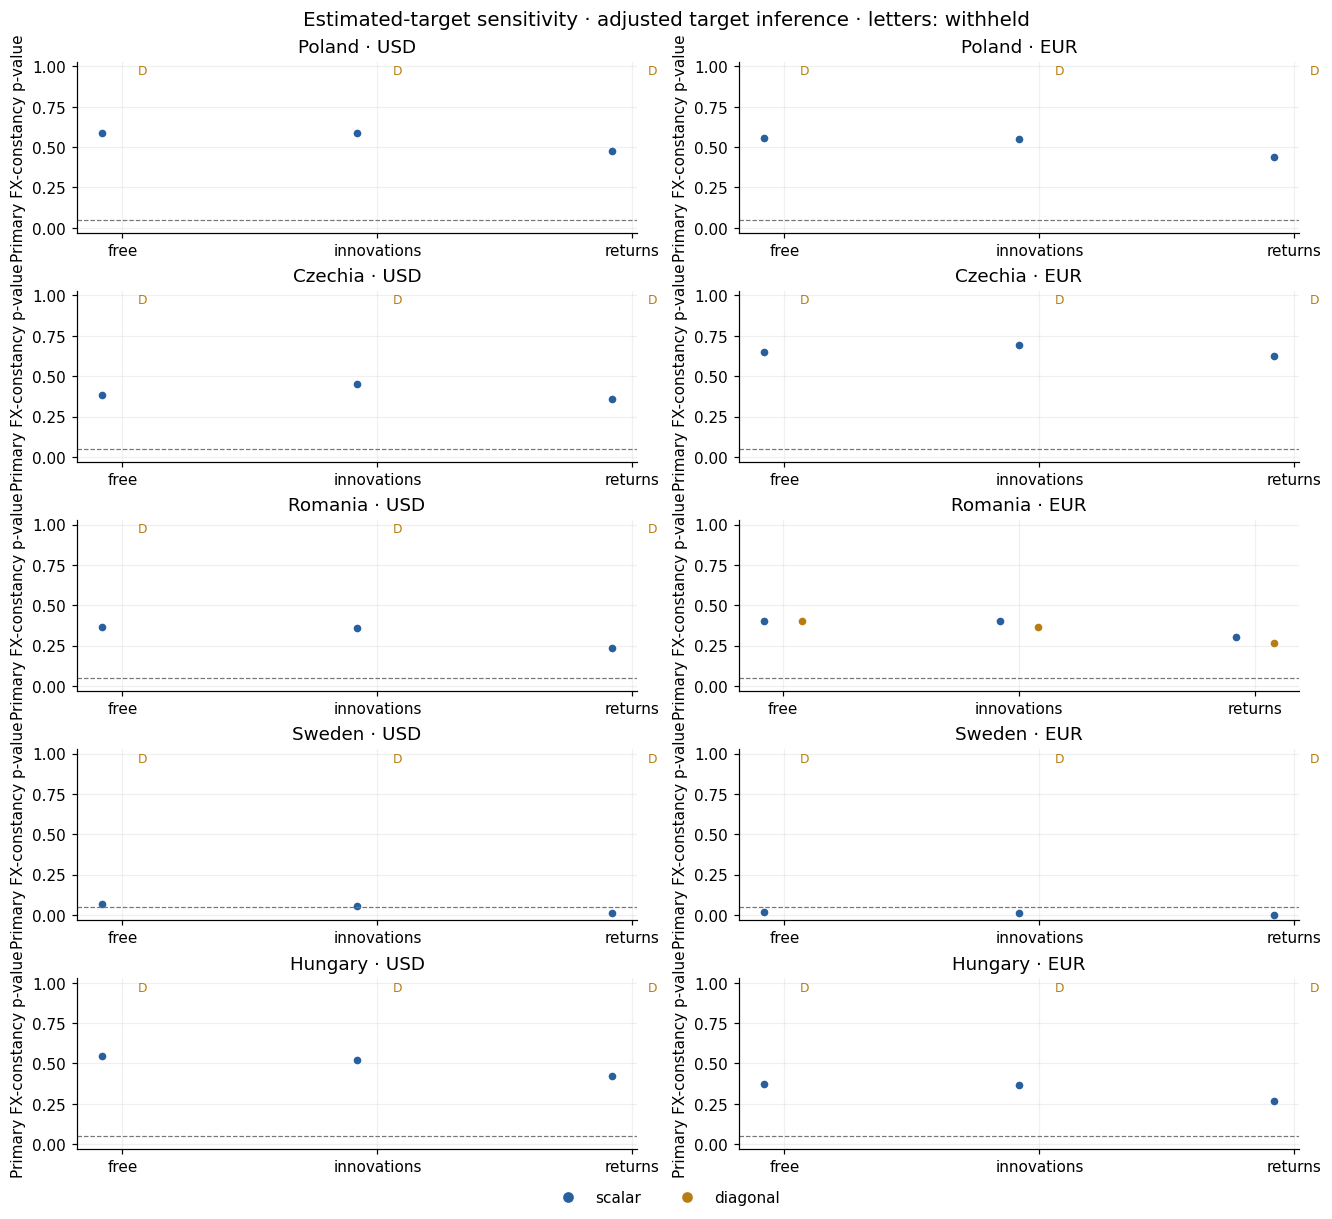

In [7]:
premium_rows,product_rows,path_diff_rows,residual_rows,cross_rows=[],[],[],[],[]
for tk,fit in fits.items():
    c=cases[tk];f=fit["filter"];tags={"country":tk[0],"perspective":tk[1],"covariance":tk[2],"target_kind":tk[3]}
    prices={"world":f["world_prices"],"national_FX":f["fx_prices"][:,0],"other_FX":f["fx_prices"][:,1],"local":f["local_prices"]}
    covs={"world":f["H"][:,2,0],"national_FX":f["H"][:,2,3],"other_FX":f["H"][:,2,4],"local":f["H"][:,2,2]}
    components={a:prices[a]*covs[a] for a in prices};total=sum(components.values())
    np.testing.assert_allclose(total,f["mu"][:,2],atol=1e-11,rtol=0)
    product_rows.extend({**tags,"component":a,"mean_price":prices[a].mean(),"mean_covariance_pp2":covs[a].mean(),"mean_premium_pp":components[a].mean(),"product_of_means_pp":prices[a].mean()*covs[a].mean(),"interaction_pp":components[a].mean()-prices[a].mean()*covs[a].mean()} for a in prices)
    premium_rows.extend({**tags,"month":str(m),**{a+"_price":v[t] for a,v in prices.items()},**{a+"_covariance_pp2":v[t] for a,v in covs.items()},**{a+"_premium_pp":v[t] for a,v in components.items()},"fitted_mean_pp":total[t],"equity_alpha_pp":0.} for t,m in enumerate(months))
    baseline=fits[(*tk[:3],"free")]["filter"]["fx_prices"]
    for j,risk in enumerate(["National FX","Other FX"]):
        x=f["fx_prices"][:,j];b=baseline[:,j];sd=b.std(ddof=1)
        path_diff_rows.append({**tags,"risk":risk,"RMSE_over_free_SD":np.sqrt(np.mean((x-b)**2))/sd if sd>1e-14 else np.nan,"mean_difference":(x-b).mean()})
    marginal,pairs=core.diagnostics(f,ASSETS,TEST_LAGS)
    residual_rows.extend({**tags,"asset":a,**r.to_dict()} for a,r in marginal.iterrows());cross_rows.extend({**tags,"pair":a,**r.to_dict()} for a,r in pairs.iterrows())
premiums,product_summary,path_comparison,residuals,cross=map(pd.DataFrame,[premium_rows,product_rows,path_diff_rows,residual_rows,cross_rows])
for frame,columns,n in [(residuals,["LB_z_p","LB_z_squared_p","ARCH_LM_p"],25),(cross,["LB_product_p"],50)]:
    for _,idx in frame.groupby(["target_kind","covariance","perspective"]).groups.items():
        assert len(idx)==n
        for col in columns:frame.loc[idx,col+"_holm"]=multipletests(frame.loc[idx,col],method="holm")[1]
primary_tests=tests.loc[((tests.target_kind.eq("free") & tests.method.eq("joint_QML")) | (tests.target_kind.ne("free") & tests.method.eq("target_adjusted"))) & tests.HAC_lag.eq(0)]
summary=fit_summary.copy()
for restriction,column in [("FX prices constant","FX_constancy_p_primary"),("FX prices jointly zero","FX_zero_function_p_primary")]:
    p=primary_tests.loc[primary_tests.restriction.eq(restriction),["country","perspective","covariance","target_kind","p_value"]].rename(columns={"p_value":column})
    summary=summary.merge(p,on=["country","perspective","covariance","target_kind"],validate="one_to_one")
figure_files=[]
def save_plot(name):
    plt.savefig(OUT/name,dpi=160,bbox_inches="tight",metadata={"Software":"Regional covariance targets notebook 31"});figure_files.append(name);plt.show();plt.close()
colors={"scalar":"#285f9e","diagonal":"#b77d13"};kinds=["free","innovations","returns"]
fig,axes=plt.subplots(5,2,figsize=(12,11),layout="constrained")
for row,country in enumerate(NAMES):
    for col,currency in enumerate(CURRENCIES):
        ax=axes[row,col]
        for j,kind in enumerate(kinds):
            for z,cov in enumerate(COVARIANCES):
                g=summary.query("country == @country and perspective == @currency and covariance == @cov and target_kind == @kind").iloc[0]
                if np.isfinite(g.FX_constancy_p_primary):ax.plot(j+(.08 if z else -.08),g.FX_constancy_p_primary,marker="o",color=colors[cov],ms=4)
                else:ax.text(j+(.08 if z else -.08),.95,"D" if z else "S",ha="center",color=colors[cov],fontsize=8)
        ax.axhline(.05,color="#777",ls="--",lw=.8);ax.set(title=f"{NAMES[country]} · {currency}",xticks=range(3),xticklabels=kinds,ylim=(-.03,1.03),ylabel="Primary FX-constancy p-value")
handles=[plt.Line2D([],[],color=colors[c],marker="o",ls="none",label=c) for c in COVARIANCES]
fig.legend(handles=handles,loc="outside lower center",ncol=2,frameon=False);fig.suptitle("Estimated-target sensitivity · adjusted target inference · letters: withheld",fontsize=13)
save_plot("01_target_FX_constancy.png")

## 6. Save the complete sensitivity and final summary

Save targets, full state/mean/price/premium paths, preliminary and targeted parameters, map Jacobians,
stacked scores/Jacobians at both steps, all bandwidths, both uncertainty calculations, feasibility
audits and any free-comparator corrections. The final regional synthesis will combine these results
with all instrument/influence checks and the original matched model catalog. No causal hedging-cost
or currency-burden conclusion follows from these decompositions.

In [8]:
tables={"input_audit.csv":input_audit,"reference_audit.csv":reference_audit,"design_audit.csv":design_audit,"conditioning_design.csv":source_design,
    "inflation_quality_flags.csv":source_quality,"implementation_checks.csv":checks,"target_audit.csv":target_audit,"free_comparator_audit.csv":free_comparator_audit,
    "free_refinements.csv":refinements,"starting_points.csv":starting_points,"fit_summary.csv":fit_summary,"inference_audit.csv":inference_audit,"restriction_tests.csv":tests,
    "price_coefficients.csv":coefficients,"risk_price_paths.csv":price_paths,"parameter_bounds.csv":parameter_bounds,"residual_diagnostics.csv":residuals,
    "cross_covariance_diagnostics.csv":cross,"price_path_comparison.csv":path_comparison,"premium_components.csv":premiums,"price_covariance_products.csv":product_summary,"summary.csv":summary}
for name,frame in tables.items():frame.to_csv(OUT/name,index=False,float_format="%.17g",lineterminator=chr(10))
parameter_files=[]
for tk,fit in fits.items():
    c=cases[tk];f=fit["filter"];info=fit["inference"];name=f"parameters_{c['id']}.npz";first=first_stages[tk[:3]]
    extra={} if tk[3]=="free" else {"target_normalized":c["target"],"free_theta":f["free_theta"],"map_jacobian":f["map_jacobian"],"PD_dual_matrix":fit["PD_dual_matrix"]}
    np.savez(OUT/name,theta=fit["theta"],first_theta=first["theta"],first_errors=first["filter"]["errors"],first_scores=first["filter"]["scores"],
        H=f["H"],mu=f["mu"],errors=f["errors"],losses=f["losses"],scores=f["scores"],target=f["target"],intercept=f["intercept"],alpha=f["alpha"],beta=f["beta"],equity_alphas=np.zeros(3),
        Hessian=info["Hessian"],Hessian_small=info["Hessian_small"],stack_Jacobian=info["stack_Jacobian"],stack_Jacobian_small=info["stack_Jacobian_small"],stack_scores=info["stack_scores"],
        **{f"covariance_{method}_HAC{lag}":e["covariance"] for (method,lag),e in info["estimates"].items()},**extra)
    parameter_files.append(name)
_,after=verify_inputs();assert input_hashes==after and engine_hashes=={n:sha((ROOT/n).read_bytes()) for n in engine_hashes}
outputs=[*tables,*figure_files,*parameter_files,*cache_files];assert len(set(outputs))==len(outputs)
metadata={"notebook":"31_regional_covariance_targeting.ipynb","model_version":MODEL_VERSION,"previous":PREVIOUS.relative_to(ROOT).as_posix(),"previous_manifest_sha256":PREVIOUS_MANIFEST_SHA,
    "first":str(months[0]),"last":str(months[-1]),"observations_per_fit":len(months),"free_references":len(first_stages),"targeted_cases":sum(k[3]!="free" for k in fits),"cases":len(fits),
    "free_refinement_events":len(refinements),"engines":engine_hashes,"input_locks":LOCK_HASHES,"input_file_hashes":input_hashes,"spec":spec,
    "settings":{"START_DYNAMICS":START_DYNAMICS,"MAX_ITER":MAX_ITER,"MAX_ITER_OVERRIDES":{"/".join(map(str,k)):v for k,v in MAX_ITER_OVERRIDES.items()},"MAX_TARGET_ROUNDS":MAX_TARGET_ROUNDS,"HAC_LAGS":HAC_LAGS,"TEST_LAGS":TEST_LAGS},
    "python":sys.executable,"python_version":platform.python_version(),"packages":versions,"outputs":{n:sha((OUT/n).read_bytes()) for n in outputs},
    "notes":["Frozen common 144 months, base, USD/EUR, five countries, scalar/diagonal BEKK; corrected FX means and zero alphas",
        "Innovation second moment is uncentered, denominator T, from each matched preliminary free-intercept model",
        "Centered returns are a different target; no silent target repair; normalized positive-intercept constraint",
        "Primary target-adjusted uncertainty propagates all stages; target-fixed uncertainty is comparison only",
        "No ordinary LR tests or reduced-stage-two AIC/BIC ranks; invalid ordinary inference withheld",
        "Earlier references and files stay pinned; any free comparator improvements recorded separately"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata,indent=2,sort_keys=True)+chr(10))
display(summary.set_index(["country","perspective","covariance","target_kind"])[["stage2_parameters","loglik","PD_margin","primary_inference_ready","FX_constancy_p_primary","FX_zero_function_p_primary"]].round(6))
display(summary.groupby(["target_kind","covariance"]).primary_inference_ready.agg(["sum","count"]))
display(Markdown(f"**Completed:** {len(fits)} cases, including {metadata['targeted_cases']} targeted fits and {len(first_stages)} free references. "
    f"Recorded {len(refinements)} free-comparator refinements separately. All {len(input_hashes):,} protected prior files remain unchanged. Saved {len(tables)} tables in `{OUT.relative_to(ROOT)}`."))

stage2_parameters       loglik  \
country perspective covariance target_kind                                   
HU      USD         scalar     free                        30 -1576.344659   
                               innovations                 15 -1576.736154   
                               returns                     15 -1576.772536   
                    diagonal   free                        38 -1567.793663   
                               innovations                 23 -1568.267086   
                               returns                     23 -1568.186904   
        EUR         scalar     free                        30 -1575.263262   
                               innovations                 15 -1575.631938   
                               returns                     15 -1575.693305   
                    diagonal   free                        38 -1569.618652   
                               innovations                 23 -1570.140882   
                               returns                     23 -1570.240652   
PL      USD         scalar     free                        30 -1501.142565   
                               innovations                 15 -1501.798363   
                               returns                     15 -1501.823607   
                    diagonal   free                        38 -1487.587242   
                               innovations                 23 -1488.688654   
                               returns                     23 -1489.090456   
        EUR         scalar     free                        30 -1500.424014   
                               innovations                 15 -1501.048961   
                               returns                     15 -1501.115886   
                    diagonal   free                        38 -1493.995388   
                               innovations                 23 -1494.936893   
                               returns                     23 -1494.942147   
CZ      USD         scalar     free                        31 -1447.598327   
                               innovations                 16 -1448.575684   
                               returns                     16 -1448.487667   
                    diagonal   free                        39 -1442.282329   
                               innovations                 24 -1446.637236   
                               returns                     24 -1445.932896   
        EUR         scalar     free                        31 -1448.236340   
                               innovations                 16 -1449.147405   
                               returns                     16 -1449.065949   
                    diagonal   free                        39 -1434.058511   
                               innovations                 24 -1443.098326   
                               returns                     24 -1443.788086   
RO      USD         scalar     free                        30 -1406.436526   
                               innovations                 15 -1407.250750   
                               returns                     15 -1407.150784   
                    diagonal   free                        38 -1392.267557   
                               innovations                 23 -1395.509500   
                               returns                     23 -1395.261757   
        EUR         scalar     free                        30 -1406.487017   
                               innovations                 15 -1407.277990   
                               returns                     15 -1407.255088   
                    diagonal   free                        38 -1402.998187   
                               innovations                 23 -1404.092506   
                               returns                     23 -1404.111652   
SE      USD         scalar     free                        30 -1466.404717   
                               innovations                 15 -146

sum  count
target_kind covariance            
free        diagonal      1     10
            scalar       10     10
innovations diagonal      1     10
            scalar       10     10
returns     diagonal      1     10
            scalar       10     10

**Completed:** 60 cases, including 40 targeted fits and 20 free references. Recorded 0 free-comparator refinements separately. All 2,379 protected prior files remain unchanged. Saved 22 tables in `output/31_regional_covariance_targeting/2014-10_2026-09/targets_f8aa2f50`.